# Ejercicio 6. Verificación de la búsqueda en una matriz ordenada

Este cuaderno acompaña al informe [`ejercicio-06.md`](ejercicio-06.md). Ejecuta
el mismo algoritmo, comprueba el invariante y el potencial, verifica la familia
del adversario y genera `ejercicio-06.png`. Las secciones siguen la numeración
del informe.

Se cuenta una consulta de tres resultados entre el valor buscado y una celda.
La construcción de matrices, el oráculo por recorrido completo y las aserciones
pertenecen a las pruebas. Para reproducir el cuaderno hacen falta Python 3,
`matplotlib` e `IPython`.


In [1]:
from itertools import product
from random import Random

import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch, Rectangle
from IPython.display import Image, display


## 1. Formulación y modelo

La entrada es una matriz cuadrada con filas y columnas no decrecientes. Se
permiten repetidos y la matriz vacía se representa por `[]`. La salida indica
si existe una celda con el valor buscado. Acceder a una celda cuesta $O(1)$ y
se cobra una unidad por llamada a `compare`.

Las siguientes funciones pertenecen a las pruebas. La validación de las
precondiciones no forma parte de la búsqueda.


In [2]:
def is_sorted_matrix(A, strict=False):
    n = len(A)
    if any(len(row) != n for row in A):
        return False
    for i in range(n):
        for j in range(n):
            if j + 1 < n:
                if strict and not A[i][j] < A[i][j + 1]:
                    return False
                if not strict and A[i][j] > A[i][j + 1]:
                    return False
            if i + 1 < n:
                if strict and not A[i][j] < A[i + 1][j]:
                    return False
                if not strict and A[i][j] > A[i + 1][j]:
                    return False
    return True


def brute_contains(A, x):
    return any(value == x for row in A for value in row)


def adversary_matrix(n):
    return [[2 * (i + j - (n - 1)) - 1 for j in range(n)]
            for i in range(n)]


assert is_sorted_matrix([])
assert is_sorted_matrix([[0, 0], [0, 0]])
assert not is_sorted_matrix([[0, 0], [0, 0]], strict=True)
assert adversary_matrix(3) == [[-5, -3, -1], [-3, -1, 1], [-1, 1, 3]]


## 2. Algoritmo

El código siguiente es idéntico al del informe. Parte de la esquina superior
derecha; una respuesta negativa descarta la columna, y una positiva, la fila.
La comparación de tres resultados se implementa con dos predicados Python;
los conteos siguientes miden llamadas a esa función.


In [3]:
def compare(x, y):
    return (x > y) - (x < y)  # -1, 0 o 1


def matrix_contains(A, x, compare=compare):
    n = len(A)
    i, j = 0, n - 1
    while i < n and j >= 0:
        r = compare(x, A[i][j])
        if r == 0:
            return True
        if r < 0:
            j -= 1
        else:
            i += 1
    return False


## 3. Invariante y correctitud

El invariante dice que toda aparición está en las filas $i,\ldots,n-1$ y
columnas $0,\ldots,j$. La versión vigilada comprueba los límites y que ninguna
celda descartada contenga $x$. En cada vuelta sin éxito verifica
$\Phi' = \Phi-1$, con $\Phi=(n-i)+(j+1)$ entero no negativo.

Se compara también la secuencia de consultas de esta versión con la del código
del informe, instrumentando únicamente su comparador.


In [4]:
class CountingCompare:
    def __init__(self):
        self.calls = []

    def __call__(self, x, y):
        result = compare(x, y)
        self.calls.append((x, y, result))
        return result


def watched_search(A, x):
    n = len(A)
    i, j = 0, n - 1
    trace = []

    def invariant():
        assert 0 <= i <= n and -1 <= j <= n - 1
        assert all(A[r][c] != x
                   for r in range(n) for c in range(n)
                   if r < i or c > j)

    invariant()
    while i < n and j >= 0:
        assert len(trace) < 2 * n - 1
        before = (n - i) + (j + 1)
        assert before >= 2
        old_i, old_j = i, j
        value = A[i][j]
        result = compare(x, value)
        if result < 0:
            j -= 1
        elif result > 0:
            i += 1
        after = (n - i) + (j + 1)
        trace.append(dict(i=old_i, j=old_j, value=value, result=result,
                          before=before, after=after, next_i=i, next_j=j))
        if result == 0:
            assert value == x and after == before
            return True, trace
        assert after >= 0 and after == before - 1
        invariant()
    assert i == n or j == -1
    assert not brute_contains(A, x)
    return False, trace


def verify_search(A, x):
    assert is_sorted_matrix(A)
    before = tuple(tuple(row) for row in A)
    counter = CountingCompare()
    actual = matrix_contains(A, x, compare=counter)
    expected = brute_contains(A, x)
    watched, trace = watched_search(A, x)
    assert actual is watched is expected
    assert counter.calls == [(x, row['value'], row['result']) for row in trace]
    assert len(counter.calls) <= max(0, 2 * len(A) - 1)
    assert tuple(tuple(row) for row in A) == before
    return actual, trace


example = adversary_matrix(3)
result, example_trace = verify_search(example, 0)
assert result is False
example_rows = [(r['i'], r['j'], r['value'], r['before'], r['after'])
                for r in example_trace]
assert example_rows == [
    (0, 2, -1, 6, 5), (1, 2, 1, 5, 4), (1, 1, -1, 4, 3),
    (2, 1, 1, 3, 2), (2, 0, -1, 2, 1),
]
print('Tabla 1. Traza de B de lado 3, buscando 0')
print('vuelta  fila  columna  valor  potencial antes  después')
for k, (i, j, value, before, after) in enumerate(example_rows, 1):
    print(f'{k:6} {i:5} {j:8} {value:6} {before:16} {after:8}')
print('ok: cinco comparaciones; región final vacía con potencial 1')


Tabla 1. Traza de B de lado 3, buscando 0
vuelta  fila  columna  valor  potencial antes  después
     1     0        2     -1                6        5
     2     1        2      1                5        4
     3     1        1     -1                4        3
     4     2        1      1                3        2
     5     2        0     -1                2        1
ok: cinco comparaciones; región final vacía con potencial 1


## 4. Costo y cota mínima por adversario

Antes de la comparación número $q$, $\Phi=2n-(q-1)\ge2$, luego
$q\le2n-1$ para $n\ge1$. La matriz

$$B[r][c]=2(r+c-(n-1))-1$$

alcanza ese costo al buscar 0: se alternan $n$ visitas a valores $-1$ en la
antidiagonal y $n-1$ visitas a valores 1.

Para la cota mínima, el adversario responde como $B$. Si no se consulta una
posición de la antidiagonal, cambiar solo ese $-1$ por 0 conserva el orden
estricto y todas las respuestas recibidas, pero cambia la salida correcta.
Así, comparando el objetivo con celdas, hacen falta al menos $n$ consultas.
Incluso comparando dos celdas por pregunta, cada comparación involucra a lo
sumo dos candidatos: el argumento da $\lceil n/2\rceil=\Omega(n)$.

Las cotas establecen optimalidad en orden asintótico. No prueban que $2n-1$
sea la constante exacta mínima para cualquier algoritmo.


In [5]:
worst_records = []
for n in range(129):
    A = adversary_matrix(n)
    assert is_sorted_matrix(A, strict=True)
    assert not brute_contains(A, 0)
    counter = CountingCompare()
    assert matrix_contains(A, 0, compare=counter) is False
    calls = len(counter.calls)
    assert calls == (2 * n - 1 if n else 0)
    assert [value for _, value, _ in counter.calls] == [-1, 1] * max(0, n - 1) + ([-1] if n else [])
    worst_records.append((n, calls))

table_sizes = [0, 1, 2, 4, 8, 16, 32, 64]
print('Tabla 2. Peor caso del recorrido y cota mínima del modelo principal')
print(' n  medido  2n-1 (n>=1)  cota mínima n')
for n in table_sizes:
    formula = str(2 * n - 1) if n else '—'
    print(f'{n:2} {worst_records[n][1]:7} {formula:>13} {n:14}')
print('ok: peor caso exacto para todos los lados entre 0 y 128')


Tabla 2. Peor caso del recorrido y cota mínima del modelo principal
 n  medido  2n-1 (n>=1)  cota mínima n
 0       0             —              0
 1       1             1              1
 2       3             3              2
 4       7             7              4
 8      15            15              8
16      31            31             16
32      63            63             32
64     127           127             64
ok: peor caso exacto para todos los lados entre 0 y 128


In [6]:
adversary_cases = 0
for n in range(9):
    baseline = adversary_matrix(n)
    diagonal = {(i, n - 1 - i) for i in range(n)}
    for mask in range(1 << n):
        A = [row[:] for row in baseline]
        changed = {(i, n - 1 - i) for i in range(n) if mask & (1 << i)}
        for i, j in changed:
            A[i][j] = 0
        assert is_sorted_matrix(A, strict=True)
        actual, _ = verify_search(A, 0)
        assert actual is bool(changed)
        for i in range(n):
            for j in range(n):
                if (i, j) in changed:
                    assert (i, j) in diagonal and baseline[i][j] == -1
                    assert A[i][j] == 0
                else:
                    # Toda consulta que no toca un candidato modificado conserva la respuesta.
                    assert A[i][j] == baseline[i][j]
                    assert compare(0, A[i][j]) == compare(0, baseline[i][j])
        adversary_cases += 1

assert adversary_cases == sum(1 << n for n in range(9)) == 511
print(f'ok: {adversary_cases} completaciones del adversario, para lados 0 a 8')
print('ok: candidatos independientes, orden estricto y respuestas indistinguibles fuera de los cambios')


ok: 511 completaciones del adversario, para lados 0 a 8
ok: candidatos independientes, orden estricto y respuestas indistinguibles fuera de los cambios


## 5. Verificación numérica

Se enumeran todas las matrices cuadradas no decrecientes de lados 0 a 3 con
valores en $\{0,2,4\}$, incluidos repetidos. Para cada una se buscan los siete
enteros desde $-1$ hasta 5. La referencia recorre todas las celdas y no usa el
orden. Se comprueban el resultado, la conservación de la entrada, el invariante,
el potencial y el número de comparaciones del algoritmo publicado.

Además, se generan diez matrices por cada lado en $\{1,2,3,4,8,16,32\}$ con
semilla fija, y se hacen cuatro consultas por matriz: dos fuera del rango, una
clave presente y un entero del rango. Son 280 búsquedas adicionales.


In [7]:
matrix_counts = []
exhaustive_searches = 0
for n in range(4):
    count = 0
    for flat in product((0, 2, 4), repeat=n * n):
        A = [list(flat[i * n:(i + 1) * n]) for i in range(n)]
        if not is_sorted_matrix(A):
            continue
        count += 1
        for x in range(-1, 6):
            verify_search(A, x)
            exhaustive_searches += 1
    matrix_counts.append(count)

assert matrix_counts == [1, 3, 20, 175]
assert exhaustive_searches == 1393
print('Matrices no decrecientes por lado 0, 1, 2 y 3:', matrix_counts)
print(f'ok: {exhaustive_searches} búsquedas exhaustivas con repetidos y casos vacíos')

rng = Random(2026)
random_searches = 0
for n in [1, 2, 3, 4, 8, 16, 32]:
    for _ in range(10):
        A = [[0] * n for _ in range(n)]
        for i in range(n):
            for j in range(n):
                above = A[i - 1][j] if i else -5
                left = A[i][j - 1] if j else -5
                A[i][j] = max(above, left) + rng.randrange(4)
        queries = [A[0][0] - 1, A[-1][-1] + 1,
                   A[rng.randrange(n)][rng.randrange(n)],
                   rng.randint(A[0][0], A[-1][-1])]
        for x in queries:
            verify_search(A, x)
            random_searches += 1

assert random_searches == 280
print(f'ok: {random_searches} búsquedas adicionales con semilla 2026')
print('ok: invariante, potencial, resultados, conteos y matriz conservada')


Matrices no decrecientes por lado 0, 1, 2 y 3: [1, 3, 20, 175]
ok: 1393 búsquedas exhaustivas con repetidos y casos vacíos
ok: 280 búsquedas adicionales con semilla 2026
ok: invariante, potencial, resultados, conteos y matriz conservada


## Figura 1

A la izquierda, el recorrido de nueve consultas sobre $B$ de lado 5. Los bordes
naranjas marcan los cinco candidatos independientes de la antidiagonal. Las
flechas alternan abajo e izquierda; 0 no aparece. A la derecha se muestran el
peor caso medido $2n-1$ y la cota mínima $n$ del modelo de comparación entre
el objetivo y una celda. Ambas funciones son lineales.


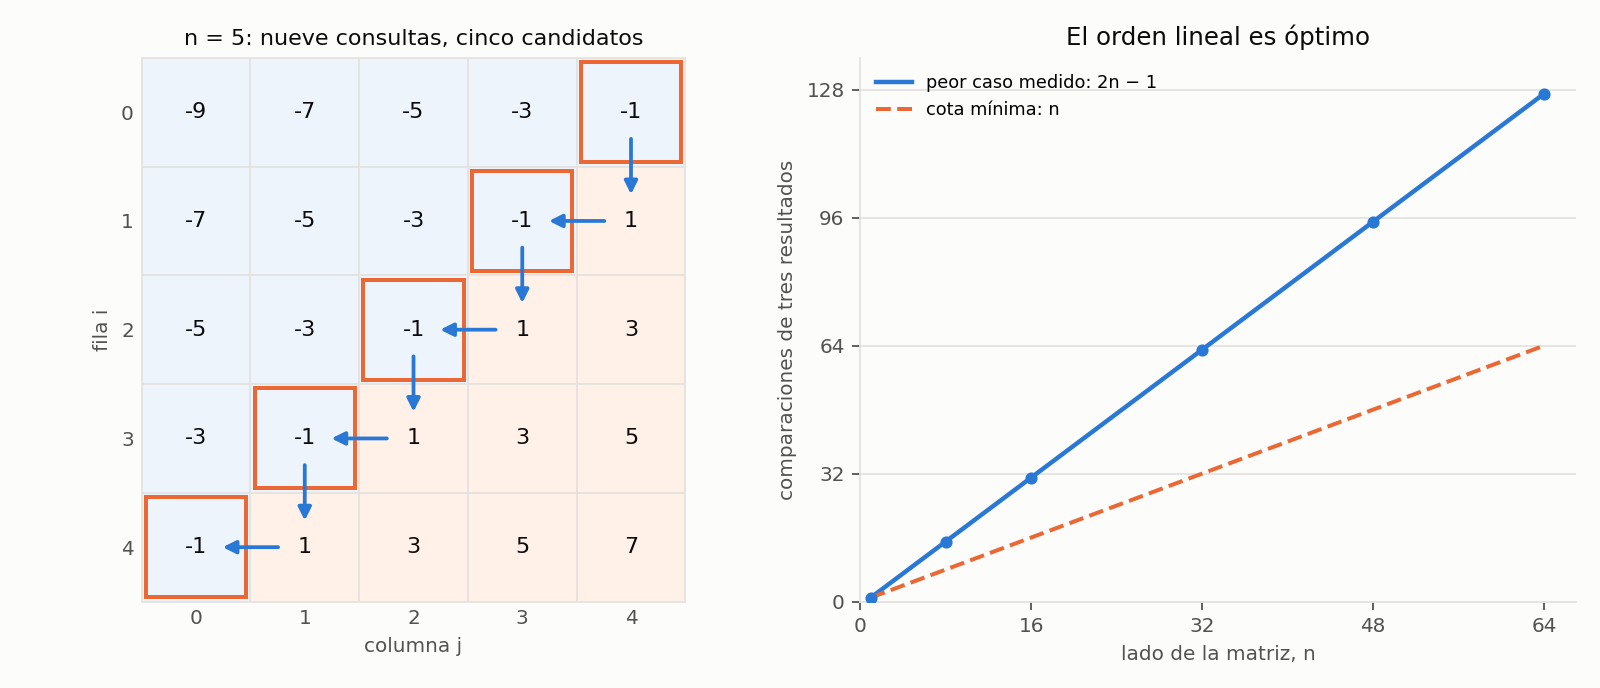

In [8]:
blue, orange = '#2a78d6', '#eb6834'
ink, secondary_ink = '#0b0b0b', '#52514e'
grid_color, background = '#e4e3df', '#fcfcfb'
fig, (ax_matrix, ax_cost) = plt.subplots(1, 2, figsize=(10, 4.3), dpi=160)
fig.patch.set_facecolor(background)

n = 5
A = adversary_matrix(n)
_, figure_trace = verify_search(A, 0)
assert len(figure_trace) == 9
for i in range(n):
    for j in range(n):
        fill = '#eef4fc' if A[i][j] < 0 else '#fff0e8'
        ax_matrix.add_patch(Rectangle((j - 0.5, i - 0.5), 1, 1,
                                      facecolor=fill, edgecolor=grid_color, lw=0.8))
        if i + j == n - 1:
            ax_matrix.add_patch(Rectangle((j - 0.46, i - 0.46), 0.92, 0.92,
                                          fill=False, edgecolor=orange, lw=1.8))
        ax_matrix.text(j, i, str(A[i][j]), ha='center', va='center',
                       fontsize=10, color=ink, zorder=5,
                       bbox=dict(facecolor=fill, edgecolor='none', pad=1.5))
for current, following in zip(figure_trace, figure_trace[1:]):
    start = (current['j'], current['i'])
    end = (following['j'], following['i'])
    ax_matrix.add_patch(FancyArrowPatch(start, end, arrowstyle='-|>',
                                        mutation_scale=12, lw=1.7, color=blue,
                                        shrinkA=12, shrinkB=12, zorder=4))
ax_matrix.set_xlim(-0.5, n - 0.5)
ax_matrix.set_ylim(n - 0.5, -0.5)
ax_matrix.set_aspect('equal')
ax_matrix.set_xticks(range(n))
ax_matrix.set_yticks(range(n))
ax_matrix.set_xlabel('columna j', color=secondary_ink, fontsize=9)
ax_matrix.set_ylabel('fila i', color=secondary_ink, fontsize=9)
ax_matrix.set_title('n = 5: nueve consultas, cinco candidatos', color=ink, fontsize=10)
ax_matrix.tick_params(colors=secondary_ink, labelsize=9, length=0)
for spine in ax_matrix.spines.values():
    spine.set_color(grid_color)

sample = worst_records[1:65]
ns = [r[0] for r in sample]
ax_cost.plot(ns, [r[1] for r in sample], color=blue, lw=2,
              label='peor caso medido: 2n − 1')
ax_cost.plot(ns, ns, color=orange, lw=1.8, ls='--', label='cota mínima: n')
markers = [1, 8, 16, 32, 48, 64]
ax_cost.scatter(markers, [worst_records[k][1] for k in markers],
                 color=blue, s=20, zorder=3)
ax_cost.set_title('El orden lineal es óptimo', color=ink, fontsize=11)
ax_cost.set_xlabel('lado de la matriz, n', color=secondary_ink, fontsize=9)
ax_cost.set_ylabel('comparaciones de tres resultados', color=secondary_ink, fontsize=9)
ax_cost.set_xticks([0, 16, 32, 48, 64])
ax_cost.set_yticks([0, 32, 64, 96, 128])
ax_cost.set_xlim(0, 67)
ax_cost.set_ylim(0, 136)
ax_cost.set_facecolor(background)
ax_cost.grid(axis='y', color=grid_color, lw=0.8)
for side in ['top', 'right']:
    ax_cost.spines[side].set_visible(False)
for side in ['left', 'bottom']:
    ax_cost.spines[side].set_color(grid_color)
ax_cost.tick_params(colors=secondary_ink, labelsize=9)
ax_cost.legend(frameon=False, fontsize=8, loc='upper left')
fig.tight_layout()
fig.savefig('ejercicio-06.png', facecolor=background)
plt.close(fig)
display(Image(filename='ejercicio-06.png'))


## 6. Conclusiones

El invariante conserva todas las apariciones dentro del rectángulo restante.
El potencial de filas más columnas baja en cada descarte y da la terminación
y la cota $2n-1$. La antidiagonal del adversario fuerza $\Omega(n)$ preguntas,
por lo que no existe un algoritmo de $o(n)$ comparaciones en el modelo.
El recorrido tiene tiempo lineal en el peor caso y memoria auxiliar constante.

Las pruebas cubren los tamaños enumerados; las demostraciones del informe
establecen los resultados para cualquier lado $n$.


In [9]:
print('Todas las comprobaciones finalizaron correctamente.')
print(f'Búsquedas exhaustivas: {exhaustive_searches}')
print(f'Búsquedas adicionales reproducibles: {random_searches}')
print(f'Matrices de peor caso: {len(worst_records)}')
print(f'Completaciones del adversario: {adversary_cases}')
print('Figura guardada en ejercicio-06.png')


Todas las comprobaciones finalizaron correctamente.
Búsquedas exhaustivas: 1393
Búsquedas adicionales reproducibles: 280
Matrices de peor caso: 129
Completaciones del adversario: 511
Figura guardada en ejercicio-06.png
